# CycleGAN: Horse ↔ Zebra (TensorFlow / Keras), epochs 1 to 100
**Everything is already saved in this notebook, so you can scroll through all the results without running anything.**

- Trained for 100 epochs on a Kaggle T4 GPU in two sessions: epochs 1 to 66 (635.3 min), then 67 to 100 (326.8 min), about 16 hours in total.
- The training log below is one continuous log of epochs 1 to 100, with the session break marked. There is one merged loss plot and one merged results comparison.
- The code is the Colab version (it saves to Google Drive and resumes automatically). A few saved lines, such as the dataset folder path, come from the Kaggle run and will differ slightly if you run it yourself.

**To run it yourself:** Runtime → Change runtime type → T4 GPU, then Run all.

In [1]:
!pip install -q tensorflow-datasets importlib_resources

## PIECE 0: Setup

In [2]:
import os
import time
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers

AUTOTUNE = tf.data.AUTOTUNE

# Hyperparameters (the standard CycleGAN settings)
IMG_SIZE = 256
JITTER_SIZE = 286
BUFFER_SIZE = 1000
BATCH_SIZE = 1
EPOCHS = 100            # use 5-10 first to check everything works
LAMBDA_CYCLE = 10.0
LAMBDA_IDENTITY = 5.0   # = 0.5 * LAMBDA_CYCLE
LR = 2e-4
BETA_1 = 0.5

# Save to Google Drive so progress survives disconnects / power cuts.
# Set USE_DRIVE = False if you are not on Colab.
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/cyclegan_output"
else:
    OUTPUT_DIR = "cyclegan_output"
os.makedirs(f"{OUTPUT_DIR}/samples", exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/checkpoints", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## PIECE 1: Data pipeline

Dataset cycle_gan downloaded and prepared to /tmp/tfds/cycle_gan/horse2zebra/3.0.0. Subsequent calls will reuse this data.


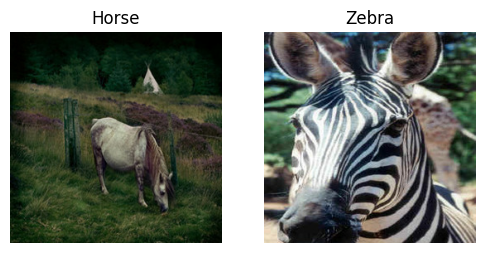

In [3]:
# trainA = horses, trainB = zebras (same for testA / testB)
dataset, info = tfds.load("cycle_gan/horse2zebra", with_info=True, as_supervised=True)
train_horses, train_zebras = dataset["trainA"], dataset["trainB"]
test_horses, test_zebras = dataset["testA"], dataset["testB"]


def normalize(img):
    """uint8 [0,255] -> float32 [-1,1] (matches the generator's tanh output)."""
    img = tf.cast(img, tf.float32)
    return img / 127.5 - 1.0


def random_jitter(img):
    """Resize up to 286x286, random-crop back to 256x256, random horizontal flip."""
    img = tf.image.resize(img, [JITTER_SIZE, JITTER_SIZE],
                          method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    img = tf.image.random_crop(img, [IMG_SIZE, IMG_SIZE, 3])
    img = tf.image.random_flip_left_right(img)
    return img


def preprocess_train(img, _label):
    return random_jitter(normalize(img))


def preprocess_test(img, _label):
    return normalize(img)


def make_train_ds(ds):
    return (ds.map(preprocess_train, num_parallel_calls=AUTOTUNE)
              .cache()
              .shuffle(BUFFER_SIZE)
              .batch(BATCH_SIZE)
              .prefetch(AUTOTUNE))


def make_test_ds(ds):
    return (ds.map(preprocess_test, num_parallel_calls=AUTOTUNE)
              .batch(BATCH_SIZE)
              .prefetch(AUTOTUNE))


train_horses_ds = make_train_ds(train_horses)
train_zebras_ds = make_train_ds(train_zebras)
test_horses_ds = make_test_ds(test_horses)
test_zebras_ds = make_test_ds(test_zebras)

# Pair the two unpaired domains; zip stops at the shorter one (1067 horses)
train_ds = tf.data.Dataset.zip((train_horses_ds, train_zebras_ds))

# Quick look at one sample from each domain
sample_horse = next(iter(test_horses_ds))
sample_zebra = next(iter(test_zebras_ds))
plt.figure(figsize=(6, 3))
for i, (img, title) in enumerate([(sample_horse, "Horse"), (sample_zebra, "Zebra")]):
    plt.subplot(1, 2, i + 1)
    plt.title(title)
    plt.imshow(img[0] * 0.5 + 0.5)
    plt.axis("off")
plt.show()

## PIECE 2: Custom layers

In [4]:
class InstanceNorm(layers.Layer):
    """Instance normalization (normalizes each image/channel independently).
    Written by hand because tensorflow_addons is deprecated."""

    def __init__(self, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        self.scale = self.add_weight(
            name="scale", shape=input_shape[-1:],
            initializer=keras.initializers.RandomNormal(1.0, 0.02), trainable=True)
        self.offset = self.add_weight(
            name="offset", shape=input_shape[-1:],
            initializer="zeros", trainable=True)

    def call(self, x):
        mean, var = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        x = (x - mean) * tf.math.rsqrt(var + self.epsilon)
        return self.scale * x + self.offset


class ReflectionPad2D(layers.Layer):
    """Pads borders by mirroring pixels, which avoids edge artifacts."""

    def __init__(self, pad=1, **kwargs):
        super().__init__(**kwargs)
        self.pad = pad

    def call(self, x):
        p = self.pad
        return tf.pad(x, [[0, 0], [p, p], [p, p], [0, 0]], mode="REFLECT")

## PIECE 3: Generator (ResNet-based, 9 residual blocks)

In [5]:
INIT = keras.initializers.RandomNormal(mean=0.0, stddev=0.02)


def residual_block(x, filters):
    skip = x
    x = ReflectionPad2D(1)(x)
    x = layers.Conv2D(filters, 3, kernel_initializer=INIT, use_bias=False)(x)
    x = InstanceNorm()(x)
    x = layers.ReLU()(x)
    x = ReflectionPad2D(1)(x)
    x = layers.Conv2D(filters, 3, kernel_initializer=INIT, use_bias=False)(x)
    x = InstanceNorm()(x)
    return layers.Add()([skip, x])


def build_generator(name, n_res_blocks=9):
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # c7s1-64
    x = ReflectionPad2D(3)(inp)
    x = layers.Conv2D(64, 7, kernel_initializer=INIT, use_bias=False)(x)
    x = InstanceNorm()(x)
    x = layers.ReLU()(x)

    # Downsample: 128, 256
    for f in (128, 256):
        x = layers.Conv2D(f, 3, strides=2, padding="same",
                          kernel_initializer=INIT, use_bias=False)(x)
        x = InstanceNorm()(x)
        x = layers.ReLU()(x)

    # Residual blocks
    for _ in range(n_res_blocks):
        x = residual_block(x, 256)

    # Upsample: 128, 64
    for f in (128, 64):
        x = layers.Conv2DTranspose(f, 3, strides=2, padding="same",
                                   kernel_initializer=INIT, use_bias=False)(x)
        x = InstanceNorm()(x)
        x = layers.ReLU()(x)

    # Output layer
    x = ReflectionPad2D(3)(x)
    x = layers.Conv2D(3, 7, activation="tanh", kernel_initializer=INIT)(x)
    return keras.Model(inp, x, name=name)

## PIECE 4: Discriminator (70x70 PatchGAN)

In [6]:
def build_discriminator(name):
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # C64 (no normalization on the first layer)
    x = layers.Conv2D(64, 4, strides=2, padding="same", kernel_initializer=INIT)(inp)
    x = layers.LeakyReLU(0.2)(x)

    # C128, C256 (stride 2), C512 (stride 1)
    for f, s in ((128, 2), (256, 2), (512, 1)):
        x = layers.Conv2D(f, 4, strides=s, padding="same",
                          kernel_initializer=INIT, use_bias=False)(x)
        x = InstanceNorm()(x)
        x = layers.LeakyReLU(0.2)(x)

    # 1-channel map of real/fake logits, one per patch (no sigmoid: we use LSGAN)
    x = layers.Conv2D(1, 4, padding="same", kernel_initializer=INIT)(x)
    return keras.Model(inp, x, name=name)


gen_G = build_generator("G_horse_to_zebra")   # X (horse) -> Y (zebra)
gen_F = build_generator("F_zebra_to_horse")   # Y (zebra) -> X (horse)
disc_X = build_discriminator("D_horse")       # judges real vs fake horses
disc_Y = build_discriminator("D_zebra")       # judges real vs fake zebras

gen_G.summary(line_length=100)
disc_X.summary(line_length=100)

Model: "G_horse_to_zebra"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 256, 256, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ reflection_pad2d            │ (None, 262, 262, 3)     │              0 │ input_layer[0][0]       │
│ (ReflectionPad2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d (Conv2D)             │ (None, 256, 256, 64)    │          9,408 │ reflection_pad2d[0][0]  │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ instance_norm               │ (None, 256, 256, 64)    │            128 │ conv2d[0][0]            │
│ (InstanceNorm)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ re_lu (ReLU)                │ (None, 256, 256, 64)    │              0 │ instance_norm[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_1 (Conv2D)           │ (None, 128, 128, 128)   │         73,728 │ re_lu[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ instance_norm_1             │ (None, 128, 128, 128)   │            256 │ conv2d_1[0][0]          │
│ (InstanceNorm)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ re_lu_1 (ReLU)              │ (None, 128, 128, 128)   │              0 │ instance_norm_1[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_2 (Conv2D)           │ (None, 64, 64, 256)     │        294,912 │ re_lu_1[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ instance_norm_2             │ (None, 64, 64, 256)     │            512 │ conv2d_2[0][0]          │
│ (InstanceNorm)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ re_lu_2 (ReLU)              │ (None, 64, 64, 256)     │              0 │ instance_norm_2[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ reflection_pad2d_1          │ (None, 66, 66, 256)     │              0 │ re_lu_2[0][0]           │
│ (ReflectionPad2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_3 (Conv2D)           │ (None, 64, 64, 256)     │        589,824 │ reflection_pad2d_1[0][… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ instance_norm_3             │ (None, 64, 64, 256)     │            512 │ conv2d_3[0][0]          │
│ (InstanceNorm)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ re_lu_3 (ReLU)              │ (None, 64, 64, 256)     │              0 │ instance_norm_3[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ reflection_pad2d_2          │ (None, 66, 66, 256)     │    

 Total params: 11,383,427 (43.42 MB)

 Trainable params: 11,383,427 (43.42 MB)

 Non-trainable params: 0 (0.00 B)

Model: "D_horse"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)                 │ (None, 256, 256, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_44 (Conv2D)                         │ (None, 128, 128, 64)            │             3,136 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ leaky_re_lu (LeakyReLU)                    │ (None, 128, 128, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_45 (Conv2D)                         │ (None, 64, 64, 128)             │           131,072 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ instance_norm_46 (InstanceNorm)            │ (None, 64, 64, 128)             │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ leaky_re_lu_1 (LeakyReLU)                  │ (None, 64, 64, 128)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_46 (Conv2D)                         │ (None, 32, 32, 256)             │           524,288 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ instance_norm_47 (InstanceNorm)            │ (None, 32, 32, 256)             │               512 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ leaky_re_lu_2 (LeakyReLU)                  │ (None, 32, 32, 256)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_47 (Conv2D)                         │ (None, 32, 32, 512)             │         2,097,152 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ instance_norm_48 (InstanceNorm)            │ (None, 32, 32, 512)             │             1,024 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ leaky_re_lu_3 (LeakyReLU)                  │ (None, 32, 32, 512)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_48 (Conv2D)                         │ (None, 32, 32, 1)               │             8,193 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 2,765,633 (10.55 MB)

 Trainable params: 2,765,633 (10.55 MB)

 Non-trainable params: 0 (0.00 B)

## PIECE 5: Losses

In [7]:
mse = keras.losses.MeanSquaredError()
mae = keras.losses.MeanAbsoluteError()


def generator_adv_loss(fake_logits):
    """Generator wants the discriminator to output 1 for its fakes (LSGAN)."""
    return mse(tf.ones_like(fake_logits), fake_logits)


def discriminator_loss(real_logits, fake_logits):
    real = mse(tf.ones_like(real_logits), real_logits)
    fake = mse(tf.zeros_like(fake_logits), fake_logits)
    return 0.5 * (real + fake)


def cycle_loss(real, cycled):
    return LAMBDA_CYCLE * mae(real, cycled)


def identity_loss(real, same):
    return LAMBDA_IDENTITY * mae(real, same)

## PIECE 6: CycleGAN model with custom training step

In [8]:
class CycleGAN(keras.Model):
    def __init__(self, gen_G, gen_F, disc_X, disc_Y):
        super().__init__()
        self.gen_G, self.gen_F = gen_G, gen_F
        self.disc_X, self.disc_Y = disc_X, disc_Y

    def compile(self, gen_G_opt, gen_F_opt, disc_X_opt, disc_Y_opt):
        super().compile()
        self.gen_G_opt, self.gen_F_opt = gen_G_opt, gen_F_opt
        self.disc_X_opt, self.disc_Y_opt = disc_X_opt, disc_Y_opt

    def call(self, x):
        return self.gen_G(x)

    def train_step(self, batch):
        real_x, real_y = batch  # horse, zebra

        with tf.GradientTape(persistent=True) as tape:
            # Forward translations and cycles
            fake_y = self.gen_G(real_x, training=True)      # horse -> zebra
            cycled_x = self.gen_F(fake_y, training=True)    # ... -> horse
            fake_x = self.gen_F(real_y, training=True)      # zebra -> horse
            cycled_y = self.gen_G(fake_x, training=True)    # ... -> zebra

            # Identity mapping (G should leave zebras alone, F should leave horses alone)
            same_x = self.gen_F(real_x, training=True)
            same_y = self.gen_G(real_y, training=True)

            # Discriminator outputs
            d_real_x = self.disc_X(real_x, training=True)
            d_fake_x = self.disc_X(fake_x, training=True)
            d_real_y = self.disc_Y(real_y, training=True)
            d_fake_y = self.disc_Y(fake_y, training=True)

            # Generator losses = adversarial + cycle + identity
            total_cycle = cycle_loss(real_x, cycled_x) + cycle_loss(real_y, cycled_y)
            g_loss = (generator_adv_loss(d_fake_y) + total_cycle
                      + identity_loss(real_y, same_y))
            f_loss = (generator_adv_loss(d_fake_x) + total_cycle
                      + identity_loss(real_x, same_x))

            # Discriminator losses
            dx_loss = discriminator_loss(d_real_x, d_fake_x)
            dy_loss = discriminator_loss(d_real_y, d_fake_y)

        # Gradients and updates
        for loss, model, opt in (
            (g_loss, self.gen_G, self.gen_G_opt),
            (f_loss, self.gen_F, self.gen_F_opt),
            (dx_loss, self.disc_X, self.disc_X_opt),
            (dy_loss, self.disc_Y, self.disc_Y_opt),
        ):
            grads = tape.gradient(loss, model.trainable_variables)
            opt.apply_gradients(zip(grads, model.trainable_variables))
        del tape

        return {"G_loss": g_loss, "F_loss": f_loss,
                "D_X_loss": dx_loss, "D_Y_loss": dy_loss}


def make_opt():
    return keras.optimizers.Adam(learning_rate=LR, beta_1=BETA_1)


model = CycleGAN(gen_G, gen_F, disc_X, disc_Y)
model.compile(make_opt(), make_opt(), make_opt(), make_opt())

## PIECE 7: Callbacks (sample images + checkpoints)

In [9]:
class SaveSamples(keras.callbacks.Callback):
    """After every epoch: save a horse->zebra->horse and zebra->horse->zebra preview
    and write the weights to disk."""

    def __init__(self, horses, zebras, n=2):
        super().__init__()
        self.horses = list(horses.take(n))
        self.zebras = list(zebras.take(n))

    def on_epoch_end(self, epoch, logs=None):
        rows = []
        for h in self.horses:
            fake_z = self.model.gen_G(h, training=False)
            rows.append(("Horse", h, "Fake zebra", fake_z,
                         "Cycled horse", self.model.gen_F(fake_z, training=False)))
        for z in self.zebras:
            fake_h = self.model.gen_F(z, training=False)
            rows.append(("Zebra", z, "Fake horse", fake_h,
                         "Cycled zebra", self.model.gen_G(fake_h, training=False)))

        fig, axes = plt.subplots(len(rows), 3, figsize=(9, 3 * len(rows)))
        for r, row in enumerate(rows):
            for c in range(3):
                title, img = row[2 * c], row[2 * c + 1]
                axes[r, c].imshow(img[0] * 0.5 + 0.5)
                axes[r, c].set_title(title, fontsize=9)
                axes[r, c].axis("off")
        plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/samples/epoch_{epoch + 1:03d}.png", dpi=100)
        plt.close(fig)

        self.model.gen_G.save_weights(f"{OUTPUT_DIR}/checkpoints/G.weights.h5")
        self.model.gen_F.save_weights(f"{OUTPUT_DIR}/checkpoints/F.weights.h5")
        self.model.disc_X.save_weights(f"{OUTPUT_DIR}/checkpoints/DX.weights.h5")
        self.model.disc_Y.save_weights(f"{OUTPUT_DIR}/checkpoints/DY.weights.h5")

        # Written last, so it only says "epoch N done" if all weights saved fine
        with open(f"{OUTPUT_DIR}/checkpoints/last_epoch.txt", "w") as f:
            f.write(str(epoch + 1))

## PIECE 8: Train

In [10]:
# --- Resume from the last completed epoch, if a checkpoint exists ---
ckpt = f"{OUTPUT_DIR}/checkpoints"
initial_epoch = 0
if os.path.exists(f"{ckpt}/last_epoch.txt"):
    with open(f"{ckpt}/last_epoch.txt") as f:
        initial_epoch = int(f.read().strip())
    gen_G.load_weights(f"{ckpt}/G.weights.h5")
    gen_F.load_weights(f"{ckpt}/F.weights.h5")
    disc_X.load_weights(f"{ckpt}/DX.weights.h5")
    disc_Y.load_weights(f"{ckpt}/DY.weights.h5")
    print(f"Resuming from epoch {initial_epoch}")
else:
    print("No checkpoint found, starting from scratch")

# EPOCHS is the TOTAL you want (set it in Piece 0), not "how many more".
start = time.time()
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    initial_epoch=initial_epoch,
    callbacks=[SaveSamples(test_horses_ds, test_zebras_ds)],
)
print(f"Training finished in {(time.time() - start) / 60:.1f} minutes")

# Loss curves
plt.figure(figsize=(8, 4))
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("CycleGAN training losses")
plt.savefig(f"{OUTPUT_DIR}/loss_curves.png", dpi=100)
plt.show()

No checkpoint found, starting from scratch
Epoch 1/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 682s 539ms/step - D_X_loss: 0.2823 - D_Y_loss: 0.2160 - F_loss: 5.6896 - G_loss: 5.1879
Epoch 2/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 575s 539ms/step - D_X_loss: 0.4380 - D_Y_loss: 0.2396 - F_loss: 7.8991 - G_loss: 9.1979
Epoch 3/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 575s 539ms/step - D_X_loss: 0.4804 - D_Y_loss: 0.1075 - F_loss: 5.7023 - G_loss: 5.6329
Epoch 4/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 575s 539ms/step - D_X_loss: 0.2553 - D_Y_loss: 0.1625 - F_loss: 6.1296 - G_loss: 5.7494
Epoch 5/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 576s 540ms/step - D_X_loss: 0.0730 - D_Y_loss: 0.0903 - F_loss: 4.4860 - G_loss: 4.3324
Epoch 6/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 577s 540ms/step - D_X_loss: 0.1635 - D_Y_loss: 0.2768 - F_loss: 4.0230 - G_loss: 3.9640
Epoch 7/100
1067/1067 ━━━━━━━━━━━━━━━━━━━━ 576s 540ms/step - D_X_loss: 0.2580 - D_Y_loss: 0.1604 - F_loss: 3.5510 - G_loss: 3.7497
Epoch 8/100
1067/1067 ━━━━━━━━━━━━━━━━━━

### Loss curves, epochs 1 to 100
One plot for the whole run. The dashed line marks where training was resumed.

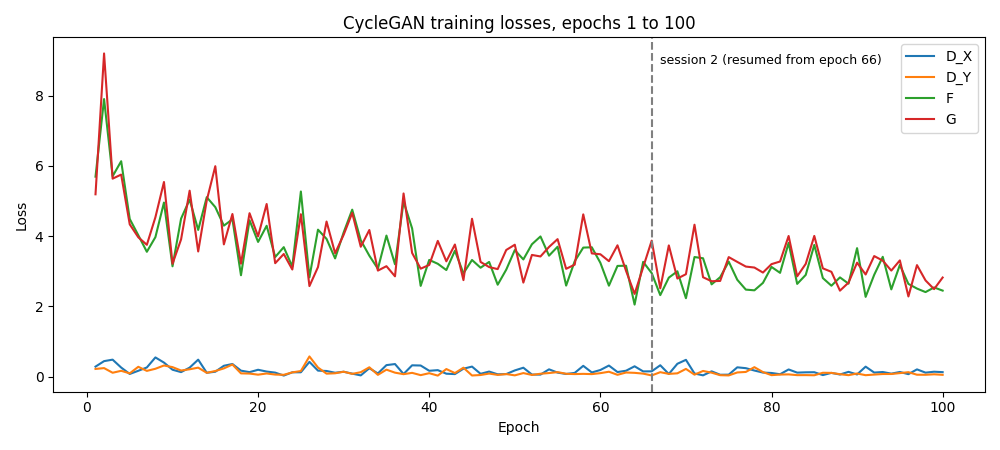

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Per-epoch training losses for the whole run (epochs 1 to 100), copied from the training logs above.
hist = {
    "D_X": [0.2823, 0.438, 0.4804, 0.2553, 0.073, 0.1635, 0.258, 0.5436, 0.397, 0.1936, 0.1256, 0.2532, 0.4804, 0.1071, 0.1363, 0.3058, 0.3565, 0.1671, 0.1247, 0.1924, 0.1414, 0.111, 0.0272, 0.12, 0.1209, 0.4172, 0.1678, 0.1574, 0.1075, 0.1364, 0.0822, 0.0321, 0.2366, 0.0876, 0.3244, 0.355, 0.0714, 0.3192, 0.3134, 0.1635, 0.1817, 0.0806, 0.069, 0.2227, 0.2826, 0.0771, 0.1413, 0.0627, 0.0701, 0.1735, 0.2508, 0.0558, 0.0547, 0.205, 0.1114, 0.0722, 0.103, 0.3043, 0.1161, 0.1856, 0.3124, 0.1271, 0.1647, 0.2911, 0.1459, 0.148, 0.3207, 0.0713, 0.3628, 0.4751, 0.0864, 0.0335, 0.1479, 0.0503, 0.0532, 0.262, 0.2378, 0.1706, 0.1127, 0.1008, 0.0647, 0.2012, 0.1109, 0.1196, 0.1224, 0.041, 0.1031, 0.0575, 0.1329, 0.0585, 0.2813, 0.1128, 0.1286, 0.082, 0.1294, 0.067, 0.2036, 0.1105, 0.1369, 0.1246],
    "D_Y": [0.216, 0.2396, 0.1075, 0.1625, 0.0903, 0.2768, 0.1604, 0.221, 0.314, 0.2676, 0.1708, 0.2063, 0.2526, 0.1055, 0.1568, 0.2313, 0.3417, 0.0897, 0.0842, 0.0527, 0.0868, 0.0557, 0.0488, 0.1178, 0.1565, 0.5716, 0.2554, 0.0819, 0.0923, 0.1367, 0.0755, 0.1231, 0.263, 0.0477, 0.1957, 0.11, 0.0669, 0.1044, 0.0393, 0.0949, 0.0259, 0.2128, 0.0989, 0.2514, 0.0294, 0.0431, 0.0841, 0.0462, 0.0698, 0.0334, 0.098, 0.045, 0.0791, 0.099, 0.1257, 0.0779, 0.0696, 0.0758, 0.0689, 0.096, 0.1365, 0.0488, 0.1143, 0.1049, 0.0826, 0.0309, 0.1237, 0.075, 0.0911, 0.2164, 0.0532, 0.1583, 0.11, 0.038, 0.0314, 0.1158, 0.1305, 0.2662, 0.1261, 0.039, 0.0558, 0.0608, 0.0394, 0.0403, 0.0359, 0.107, 0.1035, 0.0663, 0.0384, 0.0859, 0.0381, 0.0554, 0.0714, 0.0722, 0.0972, 0.1237, 0.0512, 0.0494, 0.0632, 0.0486],
    "F": [5.6896, 7.8991, 5.7023, 6.1296, 4.486, 4.023, 3.551, 3.9687, 4.9535, 3.138, 4.4958, 5.0376, 4.173, 5.1057, 4.8219, 4.2952, 4.4757, 2.8834, 4.4495, 3.8319, 4.2919, 3.4021, 3.6831, 3.1278, 5.2675, 2.823, 4.1811, 3.9181, 3.3627, 4.1019, 4.7507, 3.8778, 3.4402, 3.0687, 4.0126, 3.1953, 4.98, 4.2171, 2.5804, 3.3196, 3.2098, 3.0314, 3.5808, 2.9378, 3.3182, 3.0975, 3.2626, 2.6137, 3.0429, 3.5995, 3.3335, 3.7653, 3.9874, 3.4411, 3.6947, 2.5889, 3.2806, 3.6702, 3.6795, 3.2376, 2.5862, 3.1488, 3.1544, 2.0477, 3.2643, 2.9436, 2.3171, 2.8152, 2.9955, 2.2294, 3.4017, 3.3668, 2.6243, 2.8275, 3.2703, 2.7542, 2.4742, 2.4541, 2.6656, 3.1199, 2.9516, 3.8039, 2.6371, 2.8933, 3.7465, 2.8029, 2.5852, 2.822, 2.6442, 3.6551, 2.2679, 2.8946, 3.4081, 2.4809, 3.1763, 2.6367, 2.5041, 2.4038, 2.5361, 2.4459],
    "G": [5.1879, 9.1979, 5.6329, 5.7494, 4.3324, 3.964, 3.7497, 4.5347, 5.5388, 3.21, 3.904, 5.2904, 3.5605, 5.0144, 5.9883, 3.7617, 4.627, 3.2134, 4.6495, 3.9898, 4.9117, 3.2264, 3.4881, 3.0469, 4.6204, 2.5746, 3.116, 4.4124, 3.5097, 4.0356, 4.6579, 3.6947, 4.1711, 3.0153, 3.1411, 2.8526, 5.2116, 3.5181, 3.0703, 3.1769, 3.8614, 3.2799, 3.7583, 2.744, 4.491, 3.2626, 3.116, 3.0581, 3.6027, 3.7519, 2.6741, 3.4616, 3.418, 3.6881, 3.9112, 3.0665, 3.1848, 4.6169, 3.5049, 3.481, 3.2839, 3.7355, 3.0085, 2.3526, 3.1096, 3.868, 2.5101, 3.7327, 2.7891, 2.9129, 4.3218, 2.8263, 2.7127, 2.7214, 3.4001, 3.2633, 3.1303, 3.1027, 2.9597, 3.1994, 3.2745, 4.0008, 2.8522, 3.2071, 4.0027, 3.0794, 2.9809, 2.4449, 2.6729, 3.2412, 2.9047, 3.4293, 3.2993, 3.0159, 3.3062, 2.2793, 3.1715, 2.7361, 2.4881, 2.8184],
}
epochs = np.arange(1, 101)

plt.figure(figsize=(10, 4.5))
for name, vals in hist.items():
    plt.plot(epochs, vals, label=name)
plt.axvline(66, color="gray", linestyle="--")
plt.text(67, plt.ylim()[1] * 0.92, "session 2 (resumed from epoch 66)", fontsize=9)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CycleGAN training losses, epochs 1 to 100")
plt.legend()
plt.tight_layout()
plt.show()

## PIECE 9: Inference / evaluation on the test set
Final test translations, after epoch 100.

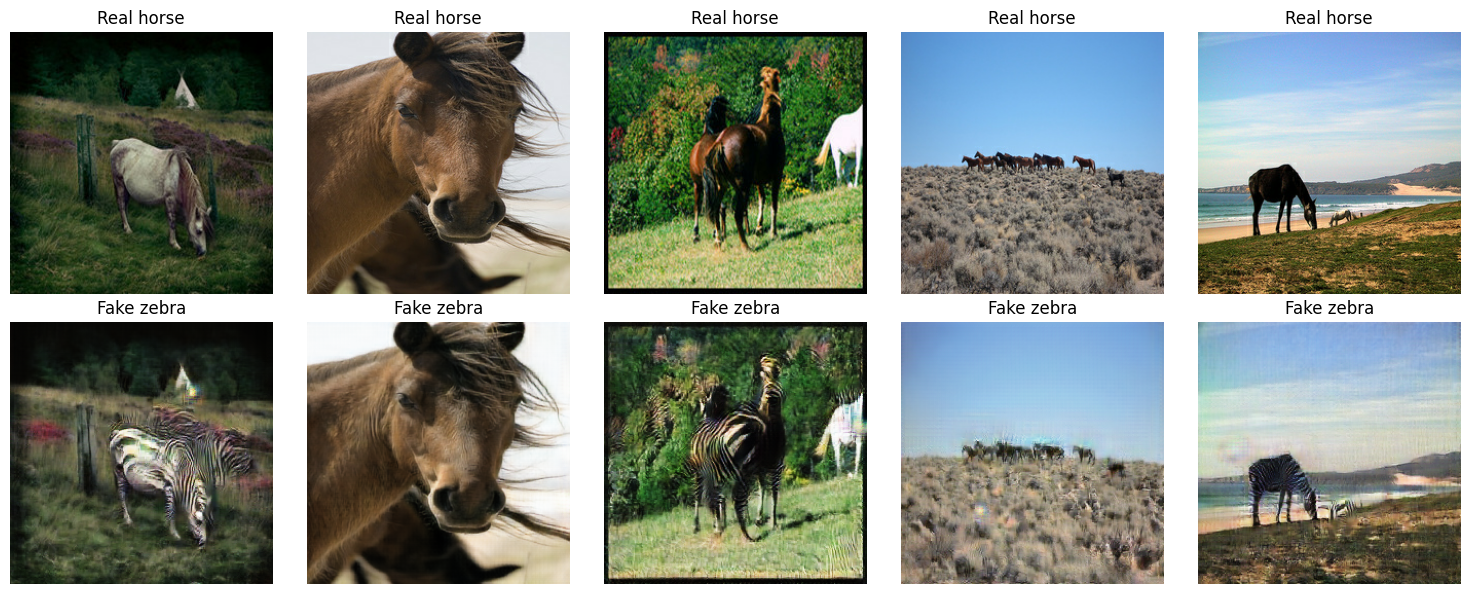

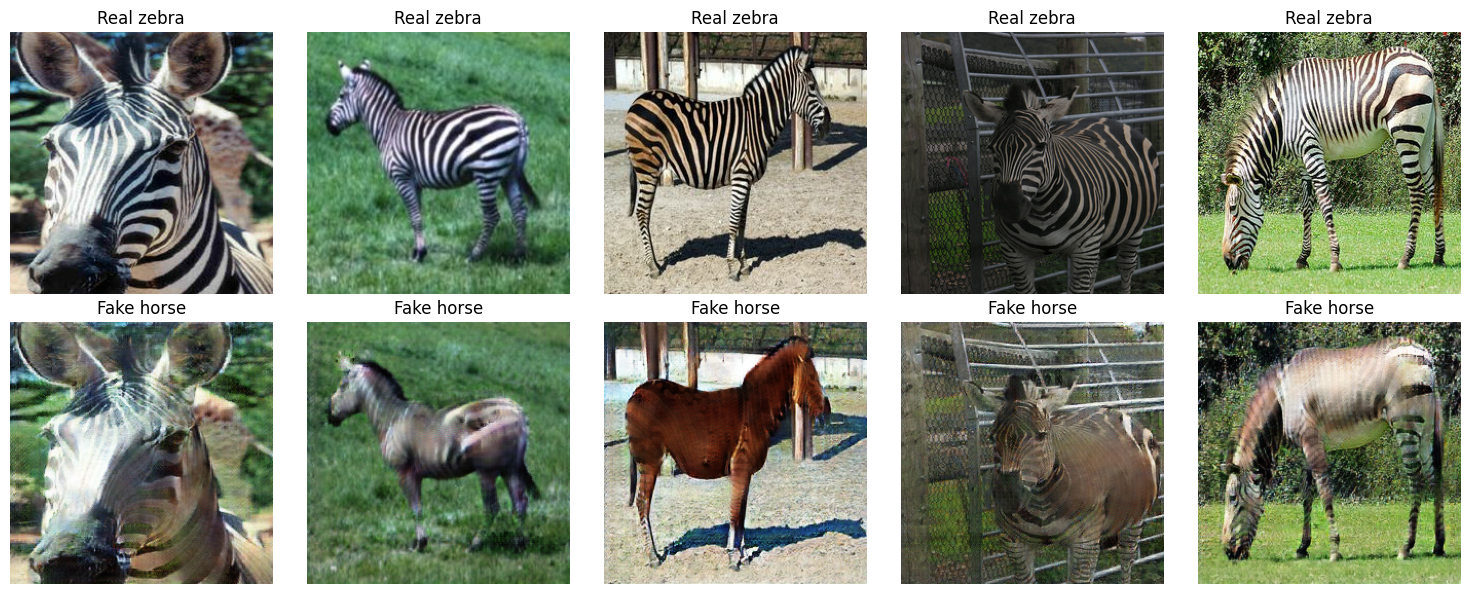

In [12]:
def show_translations(ds, generator, title_in, title_out, n=5):
    plt.figure(figsize=(3 * n, 6))
    for i, img in enumerate(ds.take(n)):
        out = generator(img, training=False)
        plt.subplot(2, n, i + 1)
        plt.imshow(img[0] * 0.5 + 0.5)
        plt.title(title_in)
        plt.axis("off")
        plt.subplot(2, n, n + i + 1)
        plt.imshow(out[0] * 0.5 + 0.5)
        plt.title(title_out)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


show_translations(test_horses_ds, gen_G, "Real horse", "Fake zebra")
show_translations(test_zebras_ds, gen_F, "Real zebra", "Fake horse")

# To reuse a trained model later without retraining:
#   gen_G = build_generator("G"); gen_G(tf.zeros([1, 256, 256, 3]))
#   gen_G.load_weights(f"{OUTPUT_DIR}/checkpoints/G.weights.h5")

### Results across training: original, epoch 66 and epoch 100
The same five test photos in each direction. A later epoch is not always better: compare photos 2 and 4 in the horse-to-zebra figure.

Horse to zebra


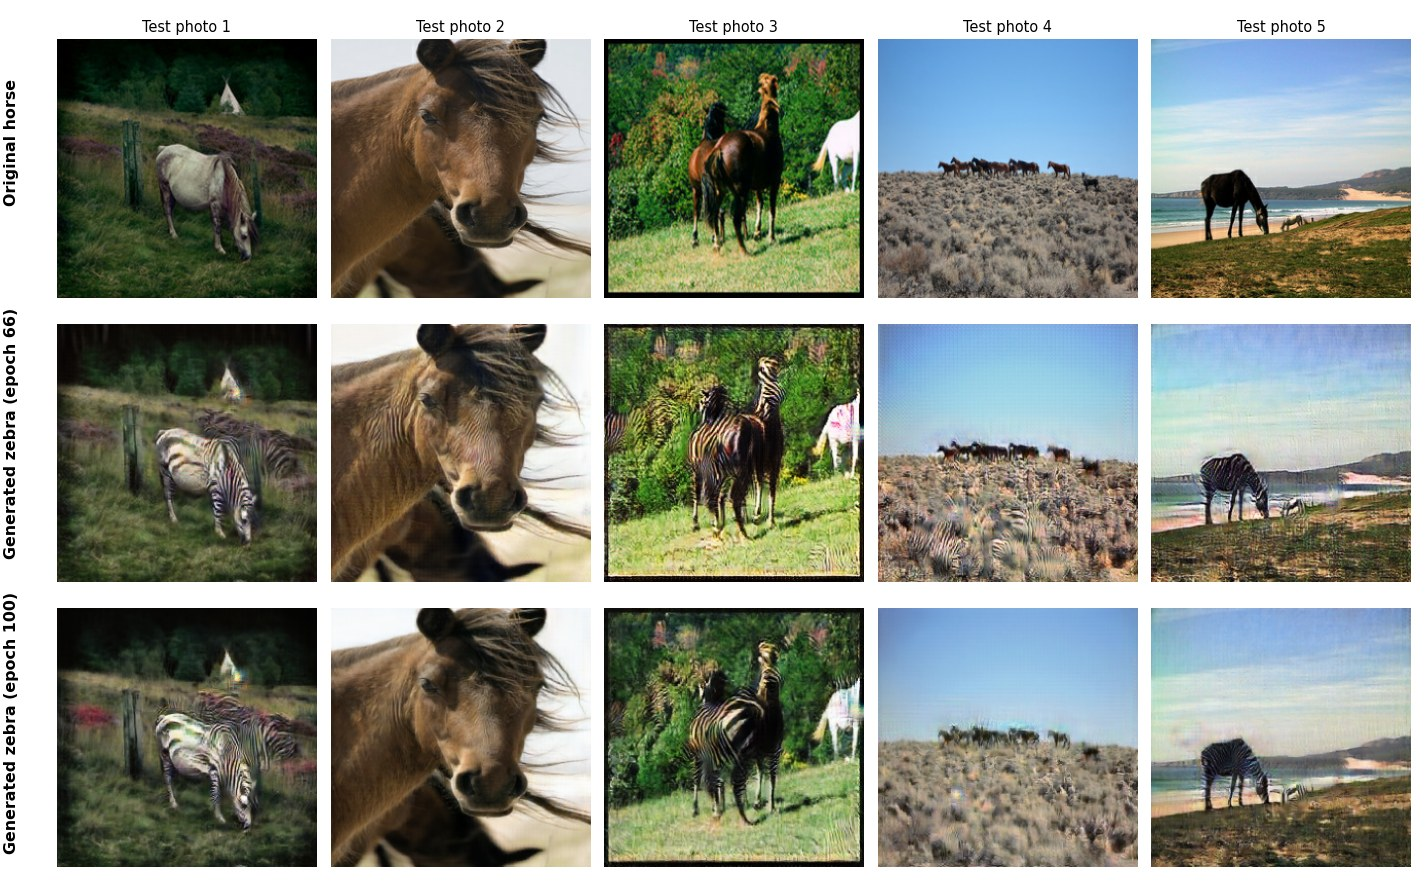

Zebra to horse


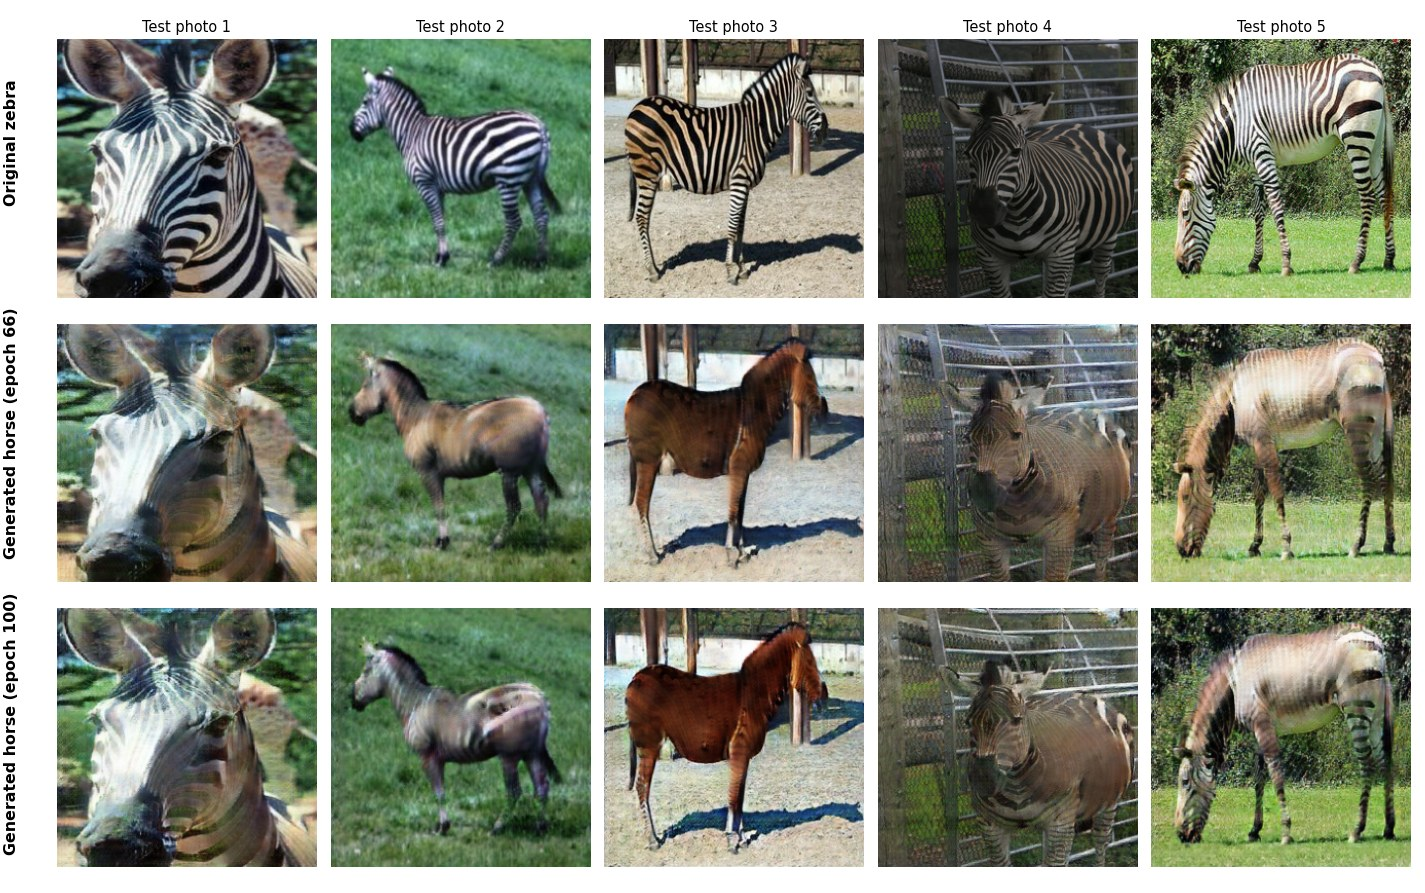

In [13]:
# Saved comparison figures built from the epoch-66 and epoch-100 test translations. Nothing to run.